# Wireless Networking and Mobile Computing

### Prerequisites

This Jupyter Notebook has been tested with Visual Studio Code, running in a local Python environment.

**Installs**

In [23]:
# --- Installs: ensure required packages are available ---
%pip install numpy scipy soundfile matplotlib imageio-ffmpeg --quiet

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


**Imports**

In [24]:
# --- Imports: libraries used in this notebook ---
import numpy as np, soundfile as sf
import matplotlib.pyplot as plt
from scipy.signal import spectrogram
from IPython.display import Audio, display

**Declarations**

Set the variables below and run the generation cell. 

- `FILE_A` is the path to the first audio file that will be analysed, e.g. `Audio/CrabRave.wav`.
- `FILE_B` is the path to the second audio file that will be analysed, e.g. `Audio/DarudeSandstorm.wav`.

In [25]:
# --- Declarations: editable variables for students ---
FILE_A = "Audio/CrabRave.wav"
FILE_B = "CrabRave_SSN.wav"

### 1. Theory
#### 1.1 Setup
This Notebook allows you to compare two audio files (FILE_A and FILE_B) in time and frequency domain, as well as a spectogram comparison.

In [26]:
# Helper Functions + Prints
db = lambda a: 20*np.log10(np.maximum(a, 1e-12))

xo, fs = sf.read(FILE_A, always_2d=True); xm, fs2 = sf.read(FILE_B, always_2d=True)
assert fs==fs2, 'Sample rate mismatch'
L = min(int(5*fs), len(xo), len(xm))
xo, xm = xo[:L], xm[:L]

for arr in (xo, xm):
    peak = np.max(np.abs(arr), axis=0, keepdims=True); peak[peak==0]=1; arr /= peak
t = np.arange(L)/fs

print(FILE_A)
display(Audio(filename=FILE_A))
print(FILE_B)
display(Audio(filename=FILE_B))


Audio/CrabRave.wav


CrabRave_SSN.wav


#### 1.2 Time Domain
Shows how the amplitude of the sound changes over time. This is what we perceive as loudness and rhythm.

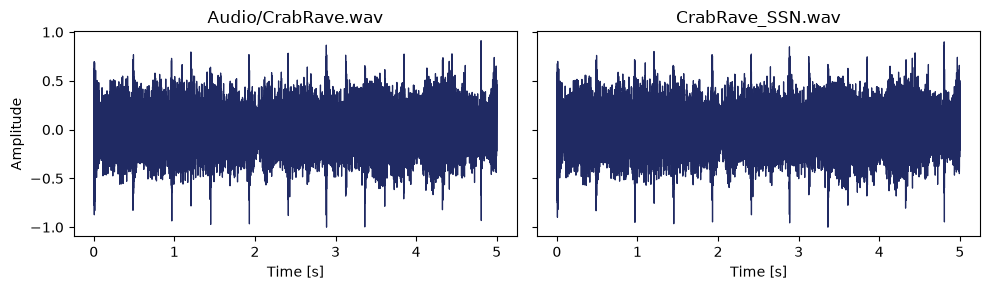

In [27]:
# Time Domain Signal Plot
fig, ax = plt.subplots(1,2,figsize=(10,3),sharey=True,sharex=True)
for a,Y,n in ((ax[0],xo, FILE_A),(ax[1],xm,FILE_B)):
    a.plot(t, Y[:,0], lw=0.9, color="#202A63")
    if Y.shape[1]>1: a.plot(t, Y[:,1], lw=.9)
    a.set_title(n); a.set_xlabel('Time [s]')
ax[0].set_ylabel('Amplitude')
plt.tight_layout(); plt.show()

#### 1.3 Frequency Domain
Displays how much energy the signal has at each frequency, helping to identify dominant tones or bands.

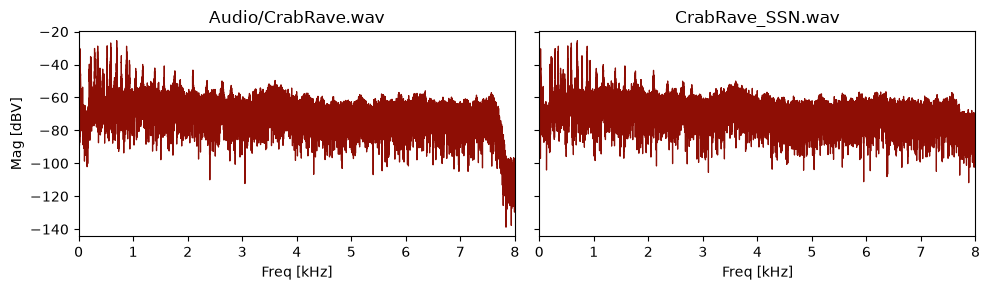

In [28]:
# Frequency Domain Signal Plot
def quick_fft(x):
    N=len(x); w=np.hanning(N); X=np.fft.rfft(x*w); f=np.fft.rfftfreq(N,1/fs)
    mag=np.abs(X); mag[0]/=2; mag=mag/(N/2)/(w.sum()/N); return f, db(mag)

fig, ax = plt.subplots(1,2,figsize=(10,3),sharey=True,sharex=True)
for a,Y,n in ((ax[0],xo,FILE_A),(ax[1],xm,FILE_B)):
    for ch in range(Y.shape[1]):
        f,m = quick_fft(Y[:,ch]); a.plot(f/1000, m, lw=.9, color='#8E0E05')
    a.set_title(n); a.set_xlabel('Freq [kHz]')
ax[0].set_ylabel('Mag [dBV]')
ax[0].set_xlim(0, (fs/2)/1000)
plt.tight_layout(); plt.show()

#### 1.4 Spectogram
Shows how the frequency content of the sound changes over time, revealing patterns such as beats or encoded data.

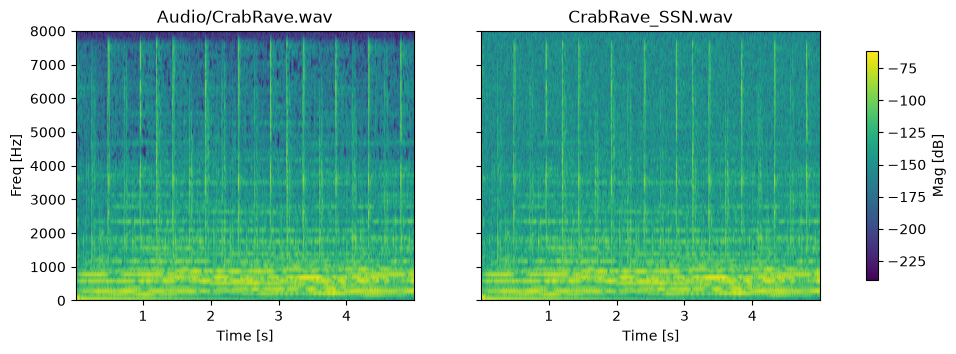

In [29]:
# Spectogram Plot
def spec(x): f,t,S = spectrogram(x, fs=fs, nperseg=256, noverlap=128, window='hann'); return f,t,db(S)
f1,t1,S1 = spec(xo[:,0]); f2,t2,S2 = spec(xm[:,0])
fig,(a0,a1)=plt.subplots(1,2,figsize=(12,3.5),sharey=True)
im0=a0.pcolormesh(t1,f1,S1,cmap='viridis',shading='gouraud'); a0.set_title(FILE_A)
im1=a1.pcolormesh(t2,f2,S2,cmap='viridis',shading='gouraud'); a1.set_title(FILE_B)
for a in (a0,a1): a.set_xlabel('Time [s]')
a0.set_ylabel('Freq [Hz]')
fig.colorbar(im1, ax=[a0,a1], shrink=.85, label='Mag [dB]')
plt.show()

#### 1.5 Tempo
The regular vertical lines in the spectrogram are the beat. Count them in your 5 s window first, then compare with the estimate below. It measures how much the spectrum *changes* from one moment to the next (a drum hit changes it a lot), and finds the time lag at which that pattern repeats best (autocorrelation). It uses 30 s, because 5 s is too short for a song that only builds up slowly.

In [30]:
# Tempo estimate: autocorrelation of the spectral change over the first 30 s
def estimate_bpm(path, seconds=30, low_bpm=70, high_bpm=180):
    x, rate = sf.read(path, always_2d=True)
    x = x[:int(seconds * rate), 0]
    f, t, S = spectrogram(x, fs=rate, nperseg=512, noverlap=384)
    change = np.maximum(np.diff(np.log1p(S * 1e4), axis=1), 0).sum(axis=0)   # onset strength
    change -= change.mean()
    ac = np.correlate(change, change, "full")[len(change) - 1:]
    lags = np.arange(len(ac)) * (t[1] - t[0])
    ok = (lags >= 60 / high_bpm) & (lags <= 60 / low_bpm)
    return 60 / lags[ok][np.argmax(ac[ok])]

for name in (FILE_A, FILE_B):
    print(f"{name}: about {estimate_bpm(name):.0f} beats per minute")

Audio/CrabRave.wav: about 125 beats per minute
CrabRave_SSN.wav: about 125 beats per minute


### 2. Your Recording
Everything above analysed files that never left the computer. Here you look at what the air, your laptop speaker and your phone microphone do to a signal.

You need two phone recordings, made in the same spot:
1. **The mystery clip** from Moodle, played on your laptop and recorded with your phone at about 30 cm (the same recording you decode in `Audio_Transmission.ipynb`).
2. **5 s of room noise**: the same setup, but nothing playing. Stay quiet while it records.

Save both next to this notebook. `.m4a`, `.mp3` and `.wav` all work. The mystery clip is `CrabRave.wav` with a hidden message added, so `CrabRave.wav` is the reference.

If a file is not found, the cells use a **simulated** recording instead, so you can see what to expect. Do not submit simulated results.

#### 2.1 Original vs. Recording

In [31]:
# INPUT
ORIGINAL_FILE  = "Audio/CrabRave.wav"
RECORDING_FILE = "Audio/Mystery.m4a"     # <-- Change this. Your phone recording of the mystery clip
NOISE_FILE     = "Audio/Room_Noise.m4a"           # <-- Change this. 5 s of room noise, same spot

import os
from scipy.signal import welch
from Audio.fsk_modem import load_audio
from Audio.audio_watermark import simulate_channel

if not os.path.exists(RECORDING_FILE):
    RECORDING_FILE = simulate_channel(ORIGINAL_FILE, "SIMULATED_Recording_50cm.wav", "50cm")
    print("No recording found: using a SIMULATED 50 cm recording. Do not submit these results.")
if not os.path.exists(NOISE_FILE):
    rng, t = np.random.default_rng(0), np.arange(5 * 16000) / 16000
    rumble = np.convolve(rng.standard_normal(len(t)), np.ones(20) / 20, "same")   # most power at low frequencies
    NOISE_FILE = "SIMULATED_Room_Noise.wav"
    sf.write(NOISE_FILE, 0.004 * rumble + 0.002 * np.sin(2 * np.pi * 50 * t) + 0.0003 * rng.standard_normal(len(t)), 16000)
    print("No room noise found: using SIMULATED noise. Do not submit these results.")

orig, orig_rate = load_audio(ORIGINAL_FILE)
rec, rec_rate = load_audio(RECORDING_FILE)
noise, noise_rate = load_audio(NOISE_FILE)
print(f"original : {len(orig) / orig_rate:5.1f} s at {orig_rate} Hz")
print(f"recording: {len(rec) / rec_rate:5.1f} s at {rec_rate} Hz")
print(f"noise    : {len(noise) / noise_rate:5.1f} s at {noise_rate} Hz")

original :  61.5 s at 16000 Hz
recording:  62.1 s at 48000 Hz
noise    :   5.8 s at 48000 Hz


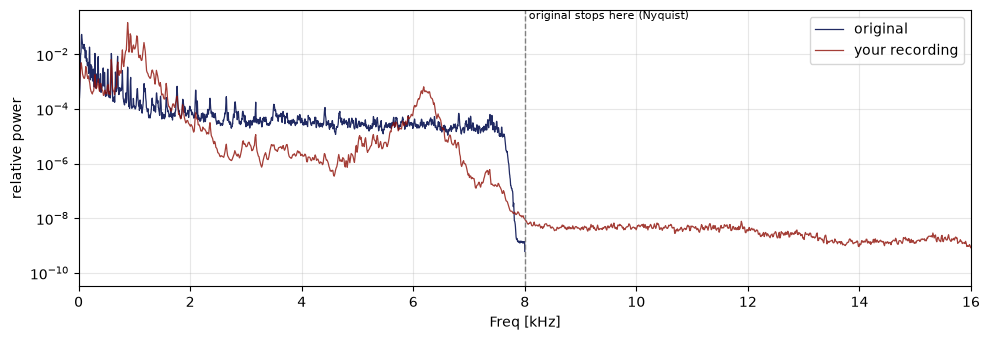

          band   original  recording   change
     0-250  Hz     -1.6 dB   -14.5 dB  -12.9 dB
   250-2000 Hz     -5.9 dB    -0.2 dB   +5.7 dB
  2000-6000 Hz    -13.5 dB   -25.6 dB  -12.1 dB
  6000-8000 Hz    -19.9 dB   -19.6 dB   +0.3 dB
energy above 8 kHz in your recording: -55.8 dB (the original has none there: this is noise and distortion added on the way)


In [32]:
# Spectrum overlay and band table. Both spectra are normalised to the same total power,
# so the plot and the table show how the *shape* changed, not how loud you played.
BANDS = [(0, 250), (250, 2000), (2000, 6000), (6000, 8000)]

def psd(x, rate):
    f, P = welch(x, fs=rate, nperseg=4096)
    return f, P / P[f <= 8000].sum()

def band_db(f, P, lo, hi):
    return 10 * np.log10(P[(f >= lo) & (f < hi)].sum() + 1e-15)

fo, Po = psd(orig, orig_rate)
fr, Pr = psd(rec, rec_rate)

plt.figure(figsize=(10, 3.5))
plt.semilogy(fo / 1000, Po, lw=0.9, label="original", color="#202A63")
plt.semilogy(fr / 1000, Pr, lw=0.9, label="your recording", color="#8E0E05", alpha=0.8)
plt.axvline(orig_rate / 2000, color="grey", ls="--", lw=1)
plt.text(orig_rate / 2000, plt.ylim()[1], " original stops here (Nyquist)", va="top", fontsize=8)
plt.xlim(0, min(rec_rate, 2 * orig_rate) / 2000)
plt.xlabel("Freq [kHz]"); plt.ylabel("relative power"); plt.legend(); plt.grid(alpha=0.3)
plt.tight_layout(); plt.show()

print(f"{'band':>14}{'original':>11}{'recording':>11}{'change':>9}")
for lo, hi in BANDS:
    a, b = band_db(fo, Po, lo, hi), band_db(fr, Pr, lo, hi)
    print(f"{lo:>6}-{hi:<5}Hz{a:>9.1f} dB{b:>8.1f} dB{b - a:>+7.1f} dB")
above = fr > orig_rate / 2 * 1.02
if above.any():
    print(f"energy above {orig_rate / 2000:.0f} kHz in your recording: {10 * np.log10(Pr[above].sum() + 1e-15):.1f} dB "
          "(the original has none there: this is noise and distortion added on the way)")

#### 2.2 Room Noise and Signal-to-Noise Ratio
A model often assumes **white noise**: equal power at every frequency, a flat line in the plot below. Real rooms rarely look like that: ventilation, traffic and footsteps put most of their power at low frequencies, and the mains supply can add a spike at 50 Hz and its multiples.

The **signal-to-noise ratio** compares the power of your recording with the power of the room alone:

$$\mathrm{SNR_{dB}} = 10\log_{10}\frac{P_\text{recording} - P_\text{noise}}{P_\text{noise}}$$

Both are measured from 100 Hz to 8 kHz, the band where the music has content. Keep your phone's recording volume and position the same for both files, otherwise the comparison is meaningless.

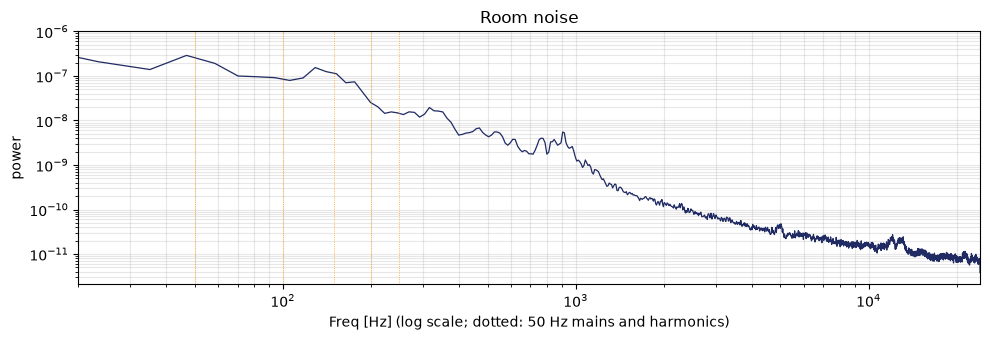

noise tilt: 100-500 Hz is +30.6 dB relative to 4-8 kHz (white noise: about 0 dB)
SNR of your recording (100 Hz - 8 kHz): 11.2 dB


In [33]:
# Room noise spectrum and SNR estimate
fn, Pn_raw = welch(noise, fs=noise_rate, nperseg=4096)
plt.figure(figsize=(10, 3.5))
plt.semilogy(fn, Pn_raw, lw=0.9, color="#202A63")
for k in range(1, 6):
    plt.axvline(50 * k, color="orange", lw=0.6, ls=":")
plt.xscale("log"); plt.xlim(20, noise_rate / 2)
plt.xlabel("Freq [Hz] (log scale; dotted: 50 Hz mains and harmonics)"); plt.ylabel("power")
plt.title("Room noise"); plt.grid(alpha=0.3, which="both"); plt.tight_layout(); plt.show()

def band_power(x, rate, lo=100, hi=8000):
    f, P = welch(x, fs=rate, nperseg=4096)
    keep = (f >= lo) & (f < hi)
    return P[keep].mean()

low = Pn_raw[(fn >= 100) & (fn < 500)].mean()
high = Pn_raw[(fn >= 4000) & (fn < 8000)].mean()
print(f"noise tilt: 100-500 Hz is {10 * np.log10(low / high):+.1f} dB relative to 4-8 kHz (white noise: about 0 dB)")

p_rec, p_noise = band_power(rec, rec_rate), band_power(noise, noise_rate)
snr_db = 10 * np.log10(max(p_rec - p_noise, 1e-20) / p_noise)
print(f"SNR of your recording (100 Hz - 8 kHz): {snr_db:.1f} dB")